<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/2_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!sudo apt-get update && sudo apt-get install -y libopencv-dev

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Fetched 3,917 B in 1s (4,857 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 58 not up

In [14]:
%%writefile odev2.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <thread>
#include <vector>

using namespace cv;
using namespace std;

// Noktasal Piksel İşlemleri: İç içe döngü ile parlaklık değiştirme ve kuantalama
void processRegion(Mat roi, int brightness_offset) {
    // Mat nesnesi referans (sığ kopya) olarak davrandığı için 'roi' üzerindeki
    // değişiklikler doğrudan orijinal resmi günceller.

    for (int r = 0; r < roi.rows; ++r) {
        for (int c = 0; c < roi.cols; ++c) {
            // 1. Doğrudan Piksel Erişimi
            int pixel_val = roi.at<uchar>(r, c);

            // 2. Parlaklık Ayarı
            pixel_val += brightness_offset;
            pixel_val = max(0, min(255, pixel_val)); // [0, 255] dinamik aralığına kırp

            // 3. Bit Derinliği Azaltma (8-bit -> 6-bit Kuantalama)
            // Tamsayı bölmesiyle 4'e bölüp, tekrar 4 ile çarparak ton basamaklanması (posterizasyon) oluşturma
            pixel_val = (pixel_val / 4) * 4;

            // Güncellenmiş değeri matrise yaz
            roi.at<uchar>(r, c) = static_cast<uchar>(pixel_val);
        }
    }
}

int main() {
    // Görüntüyü tek kanallı gri seviye okuma
    Mat img = imread("Image2.jpeg", IMREAD_GRAYSCALE);
    if (img.empty()) {
        cout << "Gorsel bulunamadi! Lutfen 'test_image.jpg' dosyasini yukleyin." << endl;
        return -1;
    }

    int h = img.rows;
    int w = img.cols;
    int half_h = h / 2;
    int half_w = w / 2;

    // Görüntüyü 4 parçaya bölme (Region of Interest - ROI kullanımı)
    Mat q1 = img(Rect(0, 0, half_w, half_h));                   // 1. Bölge: Sol Üst
    Mat q2 = img(Rect(half_w, 0, w - half_w, half_h));          // 2. Bölge: Sağ Üst
    Mat q3 = img(Rect(0, half_h, half_w, h - half_h));          // 3. Bölge: Sol Alt
    Mat q4 = img(Rect(half_w, half_h, w - half_w, h - half_h)); // 4. Bölge: Sağ Alt

    // 4 ayrı Thread oluşturma ve farklı parlaklık parametreleri geçme
    thread t1(processRegion, q1, 50);   // Sol Üst: Parlaklığı +50 artır ve 6-bit'e kuantala
    thread t2(processRegion, q2, 100);  // Sağ Üst: Parlaklığı +100 artır ve 6-bit'e kuantala
    thread t3(processRegion, q3, -30);  // Sol Alt: Parlaklığı -30 azalt ve 6-bit'e kuantala
    thread t4(processRegion, q4, -80);  // Sağ Alt: Parlaklığı -80 azalt ve 6-bit'e kuantala

    t1.join();
    t2.join();
    t3.join();
    t4.join();

    imwrite("multi_thread_quantized.jpg", img);
    cout << "[BASARILI] 4 thread ile matris taramasi, parlaklik ayari ve kuantalama tamamlandi." << endl;
    cout << "Sonuc 'multi_thread_quantized.jpg' olarak kaydedildi." << endl;

    return 0;
}

Overwriting odev2.cpp


In [15]:
!g++ -o odev2 odev2.cpp `pkg-config --cflags --libs opencv4` -pthread
!./odev2

[BASARILI] 4 thread ile matris taramasi, parlaklik ayari ve kuantalama tamamlandi.
Sonuc 'multi_thread_quantized.jpg' olarak kaydedildi.


--- Orijinal Resim ---


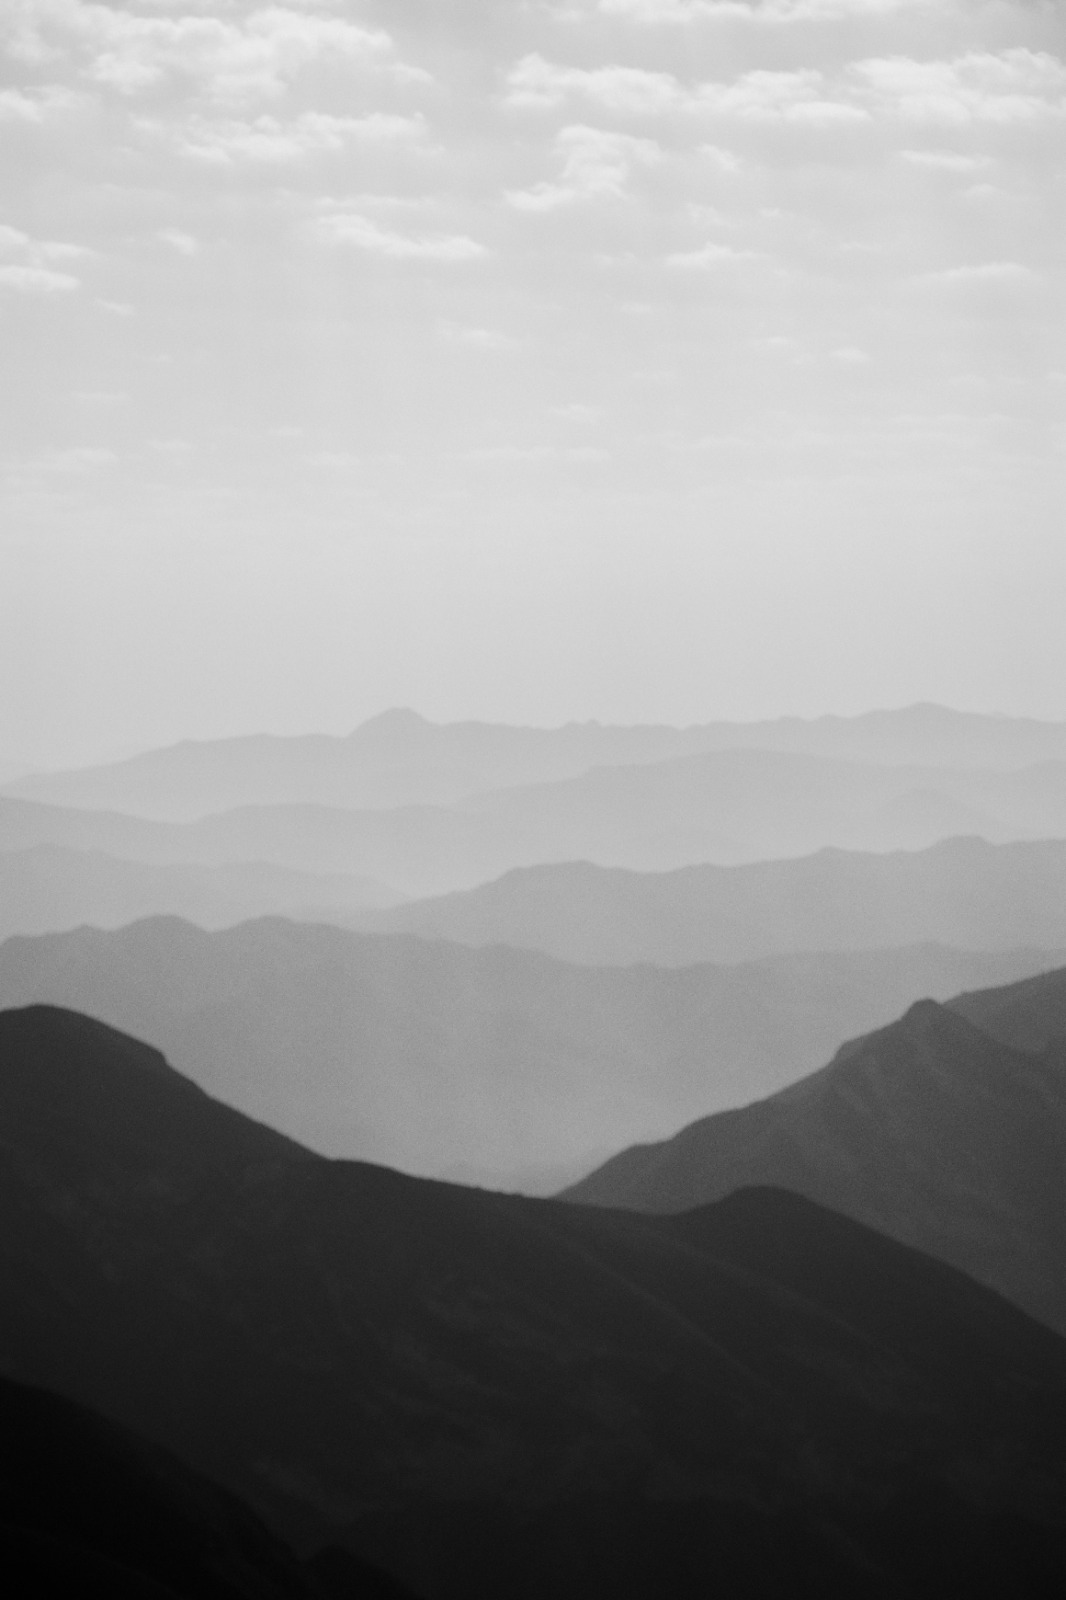

--- Multi Thread Quantize Sonrası Resim ---


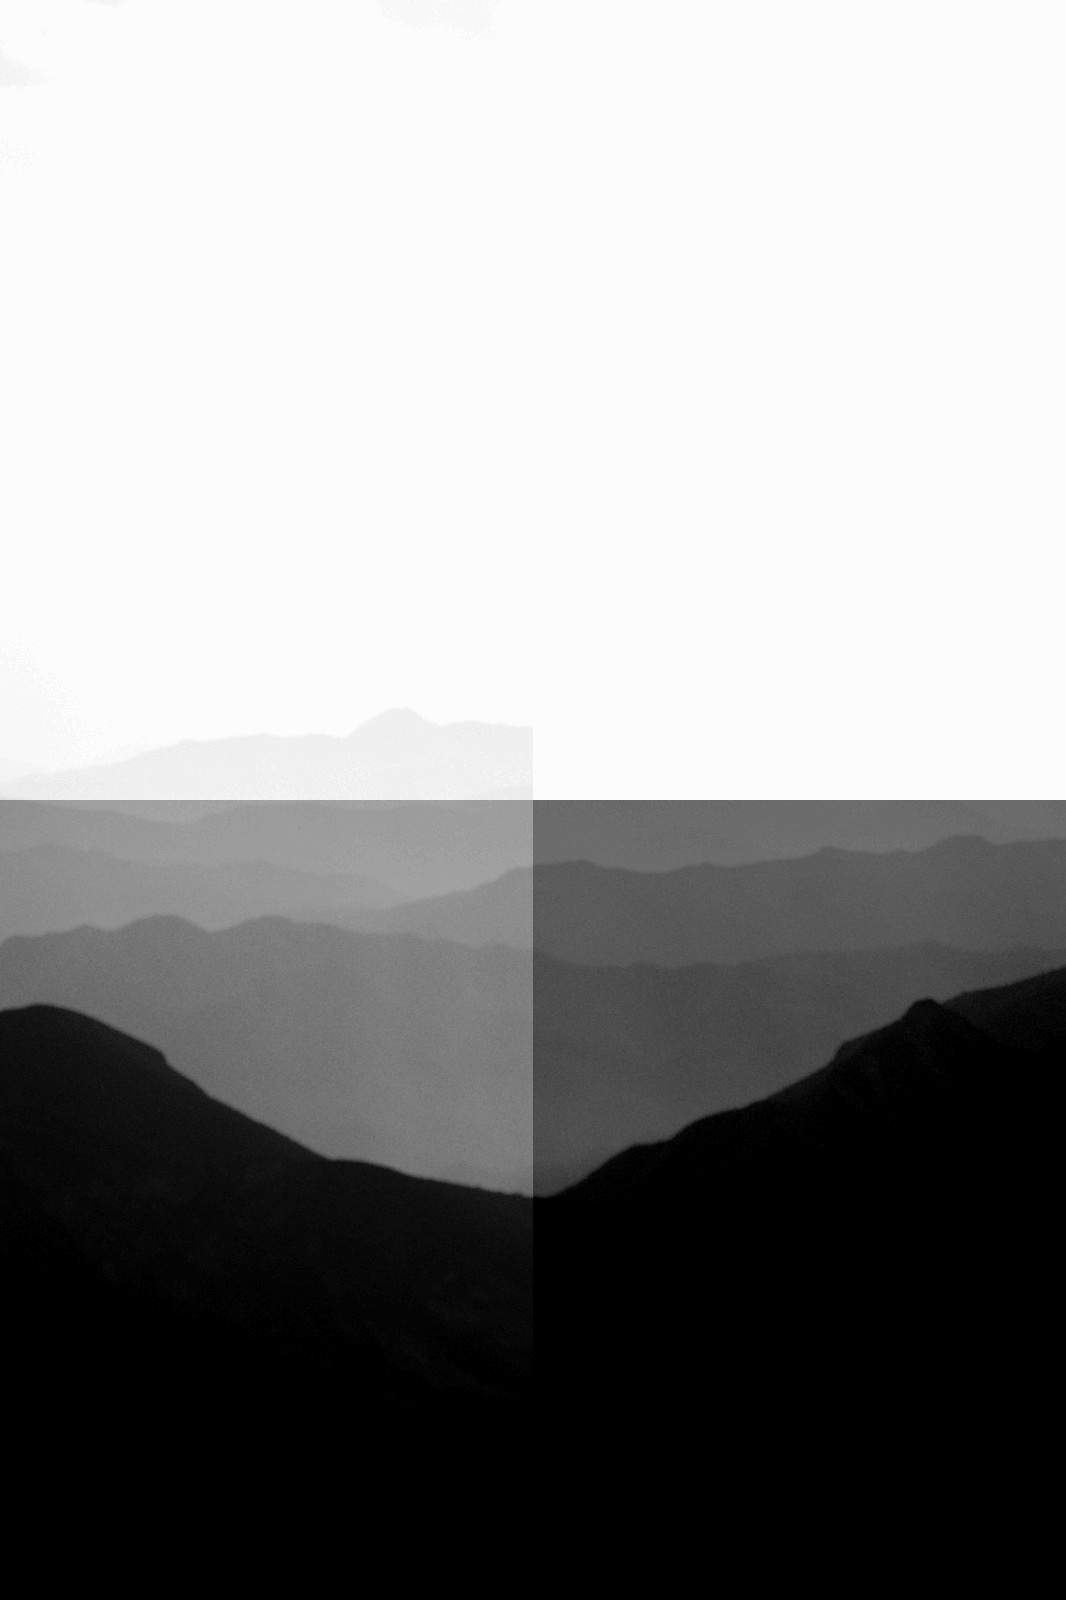

In [16]:
from IPython.display import Image, display

print("--- Orijinal Resim ---")
display(Image('Image2.jpeg'))

print("--- Multi Thread Quantize Sonrası Resim ---")
display(Image('multi_thread_quantized.jpg'))